# Section 01: Custom CNN models

### Data loading and preprocessing

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import torch
import pandas as pd
import torch.nn as nn
import matplotlib.pyplot as plt
from torchinfo import summary
from models.standard_cnn import StandardCNN
from models.lightweight_cnn import LightweightCNN
from data_prep import create_dataloaders
from utils import (
    count_parameters,
    train_model,
    evaluate_model,
    plot_training_history,
    plot_confusion_matrix,
    model_size_kb,
)

In [2]:
DATASET_DIR = PROJECT_ROOT / "data" / "EuroSAT_RGB"

BATCH_SIZE = 64
NUM_EPOCHS = 20
LEARNING_RATE = 0.001

SEED = 26
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


In [3]:
train_loader, val_loader, test_loader, class_names, mean, std = create_dataloaders(
    dataset_dir=DATASET_DIR,
    batch_size=BATCH_SIZE,
    seed=SEED,
    image_size=64,
)

print("Training mean:", mean.tolist())
print("Training std: ", std.tolist())
print("Training:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Testing:", len(test_loader.dataset))

Training mean: [0.34376397728919983, 0.3799758851528168, 0.40765735507011414]
Training std:  [0.2026132196187973, 0.13695679605007172, 0.11558672785758972]
Training: 18900
Validation: 4050
Testing: 4050


### Custom Architecture Design
#### Model A: Standard CNN

In [ ]:
model_a = StandardCNN(num_classes=len(class_names)).to(DEVICE)

summary(model_a, input_size=(1, 3, 64, 64))
print(f"Model A trainable parameters: {count_parameters(model_a):,}")
print(f"Model A size: {model_size_kb(model_a):.2f} KB")

Model A trainable parameters: 914,122
Model A size: 3570.79 KB


#### Model B: Lightweight CNN

In [ ]:
model_b = LightweightCNN(num_classes=len(class_names)).to(DEVICE)

summary(model_b, input_size=(1, 3, 64, 64))
print(f"Model B trainable parameters: {count_parameters(model_b):,}")
print(f"Model B size: {model_size_kb(model_b):.2f} KB")

Model B trainable parameters: 59,301
Model B size: 231.64 KB


### Optimizer Selection and Tuning

In [ ]:
NUM_EPOCHS = 20

# Create one initial set of weights for a fair comparison
torch.manual_seed(SEED)
initial_model = StandardCNN(num_classes=10)
initial_weights = initial_model.state_dict()

criterion = nn.CrossEntropyLoss()

optimizer_configs = {
    "Adam": {"name": "Adam", "lr": 0.001},
    "SGD": {"name": "SGD", "lr": 0.01},
    "SGD + Momentum": {
        "name": "SGD_Momentum",
        "lr": 0.01,
        "momentum": 0.9,
    },
}

histories = {}
comparison = []

for experiment, config in optimizer_configs.items():
    # Reset the model to identical initial weights
    model = StandardCNN(num_classes=10).to(DEVICE)
    model.load_state_dict(initial_weights)

    if config["name"] == "Adam":
        optimizer = torch.optim.Adam(
            model.parameters(), lr=config["lr"]
        )
    elif config["name"] == "SGD":
        optimizer = torch.optim.SGD(
            model.parameters(), lr=config["lr"]
        )
    else:
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=config["lr"],
            momentum=config["momentum"],
        )

    # Reset RNG for comparable shuffled batches
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    print(f"\nExperiment: {experiment}")

    history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=DEVICE,
        num_epochs=NUM_EPOCHS,
    )

    histories[experiment] = history

    comparison.append({
        "Optimizer": experiment,
        "Learning Rate": config["lr"],
        "Best Validation Accuracy (%)":
            100 * max(history["val_accuracy"]),
        "Final Validation Loss": history["val_loss"][-1],
        "Avg. Epoch Time (s)":
            sum(history["epoch_time"]) / len(history["epoch_time"]),
    })


Experiment: Adam
Epoch [01/10] Train Loss: 1.0601 | Train Acc: 0.5986 | Val Loss: 0.7958 | Val Acc: 0.7286 | Time: 101.28s
Epoch [02/10] Train Loss: 0.6068 | Train Acc: 0.7821 | Val Loss: 0.5394 | Val Acc: 0.8054 | Time: 91.42s
Epoch [03/10] Train Loss: 0.4874 | Train Acc: 0.8268 | Val Loss: 0.4770 | Val Acc: 0.8249 | Time: 93.36s
Epoch [04/10] Train Loss: 0.3937 | Train Acc: 0.8606 | Val Loss: 0.3846 | Val Acc: 0.8728 | Time: 87.43s
Epoch [05/10] Train Loss: 0.3304 | Train Acc: 0.8848 | Val Loss: 0.3272 | Val Acc: 0.8842 | Time: 83.79s
Epoch [06/10] Train Loss: 0.2593 | Train Acc: 0.9107 | Val Loss: 0.3225 | Val Acc: 0.8881 | Time: 87.07s
Epoch [07/10] Train Loss: 0.2229 | Train Acc: 0.9216 | Val Loss: 0.2740 | Val Acc: 0.9044 | Time: 89.55s
Epoch [08/10] Train Loss: 0.1889 | Train Acc: 0.9340 | Val Loss: 0.3468 | Val Acc: 0.8886 | Time: 94.09s
Epoch [09/10] Train Loss: 0.1626 | Train Acc: 0.9433 | Val Loss: 0.2360 | Val Acc: 0.9220 | Time: 94.07s
Epoch [10/10] Train Loss: 0.1402 | T

,Optimizer,Learning Rate,Best Validation Accuracy (%),Final Validation Loss,Avg. Epoch Time (s)
0,Adam,0.001,92.1975,0.2697,90.9284
2,SGD + Momentum,0.010,89.9506,0.3222,76.5776
1,SGD,0.010,71.3333,0.7976,90.8723


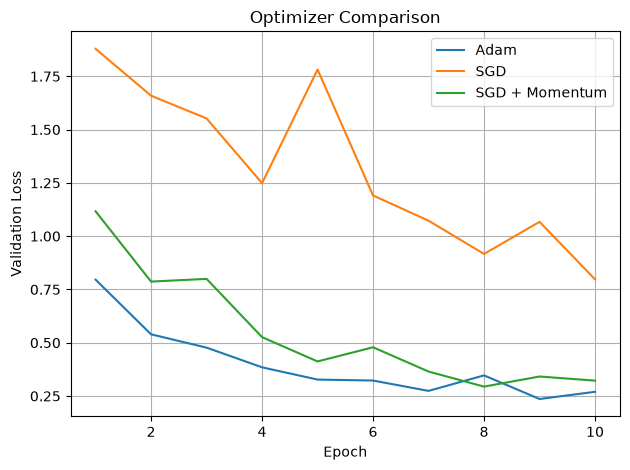

In [11]:
comparison_df = pd.DataFrame(comparison)
comparison_df = comparison_df.sort_values(
    "Best Validation Accuracy (%)", ascending=False
)

display(comparison_df.round(4))

for name, history in histories.items():
    plt.plot(
        range(1, NUM_EPOCHS + 1),
        history["val_loss"],
        label=name,
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Optimizer Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Custom Model Training and Evaluation
#### Model A: Standard CNN

In [ ]:
model_a = StandardCNN(num_classes=len(class_names)).to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_a.parameters(),
    lr=LEARNING_RATE
)

history_a = train_model(
    model=model_a,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=DEVICE,
    num_epochs=NUM_EPOCHS,
)

In [ ]:
plot_training_history(history_a, model_name="Model A")

results_a = evaluate_model(model_a, test_loader, device=DEVICE)
print(f"Test Accuracy : {results_a['accuracy']:.4f}")
print(f"Test Precision: {results_a['precision']:.4f}")
print(f"Test Recall   : {results_a['recall']:.4f}")

plot_confusion_matrix(
    results_a["confusion_matrix"],
    class_names,
    model_name="Model A"
)

#### Model B: Lightweight CNN

In [ ]:
model_b = LightweightCNN(num_classes=len(class_names)).to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_b.parameters(),
    lr=LEARNING_RATE
)

history_b = train_model(
    model=model_b,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=DEVICE,
    num_epochs=NUM_EPOCHS,
)

In [ ]:
plot_training_history(history_b, model_name="Model B")

results_b = evaluate_model(model_b, test_loader, device=DEVICE)
print(f"Test Accuracy : {results_b['accuracy']:.4f}")
print(f"Test Precision: {results_b['precision']:.4f}")
print(f"Test Recall   : {results_b['recall']:.4f}")

plot_confusion_matrix(
    results_b["confusion_matrix"],
    class_names,
    model_name="Model B"
)